In [2]:
import pandas as pd
import numpy as np

url = "https://raw.githubusercontent.com/jakevdp/data-CDCbirths/master/births.csv"
births = pd.read_csv(url)

display(births.head())
print("Shape:", births.shape)
print("\nColumn data types:")
print(births.dtypes)


births["decade"] = 10 * (births["year"] // 10)

decade_gender = pd.pivot_table(
    births,
    values="births",
    index="decade",
    columns="gender",
    aggfunc="sum"
)

display(decade_gender)
births["decade"] = 10 * (births["year"] // 10)

decade_gender = pd.pivot_table(
    births,
    values="births",
    index="decade",
    columns="gender",
    aggfunc="sum"
)

display(decade_gender)
print("Male births exceed female births in every decade:",
      (decade_gender["M"] > decade_gender["F"]).all())

decade_gender["M_to_F_ratio"] = decade_gender["M"] / decade_gender["F"]
decade_gender["Male_excess_percent"] = (
    (decade_gender["M"] - decade_gender["F"]) / decade_gender["F"] * 100
)

display(decade_gender)

,year,month,day,gender,births
0,1969,1,1.0,F,4046
1,1969,1,1.0,M,4440
2,1969,1,2.0,F,4454
3,1969,1,2.0,M,4548
4,1969,1,3.0,F,4548


Shape: (15547, 5)

Column data types:
year        int64
month       int64
day       float64
gender     object
births      int64
dtype: object


gender,F,M
decade,,
1960,1753634,1846572
1970,16263075,17121550
1980,18310351,19243452
1990,19479454,20420553
2000,18229309,19106428


gender,F,M
decade,,
1960,1753634,1846572
1970,16263075,17121550
1980,18310351,19243452
1990,19479454,20420553
2000,18229309,19106428


Male births exceed female births in every decade: True


gender,F,M,M_to_F_ratio,Male_excess_percent
decade,,,,
1960,1753634,1846572,1.052997,5.299738
1970,16263075,17121550,1.052787,5.278676
1980,18310351,19243452,1.050960,5.096030
1990,19479454,20420553,1.048312,4.831239
2000,18229309,19106428,1.048116,4.811587


In [4]:
print("Male births exceed female births in every decade:",
      (decade_gender["M"] > decade_gender["F"]).all())

decade_gender["M_to_F_ratio"] = decade_gender["M"] / decade_gender["F"]
decade_gender["Male_excess_percent"] = (
    (decade_gender["M"] - decade_gender["F"]) / decade_gender["F"] * 100
)

display(decade_gender)

Male births exceed female births in every decade: True


gender,F,M,M_to_F_ratio,Male_excess_percent
decade,,,,
1960,1753634,1846572,1.052997,5.299738
1970,16263075,17121550,1.052787,5.278676
1980,18310351,19243452,1.050960,5.096030
1990,19479454,20420553,1.048312,4.831239
2000,18229309,19106428,1.048116,4.811587


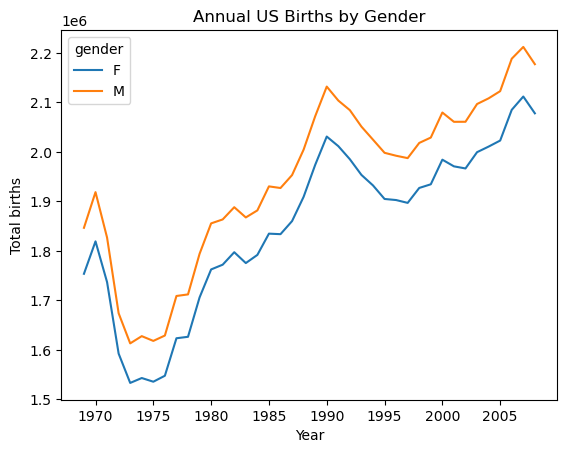

In [5]:
year_gender = pd.pivot_table(
    births,
    values="births",
    index="year",
    columns="gender",
    aggfunc="sum"
)

year_gender.plot(
    title="Annual US Births by Gender",
    xlabel="Year",
    ylabel="Total births"
);

In [6]:
Q1, Q3 = np.percentile(births["births"], [25, 75])

mu = np.median(births["births"])

sig = 0.74 * (Q3 - Q1)

print("Q1:", Q1)
print("Median (mu):", mu)
print("Q3:", Q3)
print("Robust standard deviation (sig):", sig)

Q1: 4358.0
Median (mu): 4814.0
Q3: 5289.5
Robust standard deviation (sig): 689.31


In [7]:
clean_births = births.query(
    "@mu - 5 * @sig <= births <= @mu + 5 * @sig"
).copy()

print("Rows before cleaning:", len(births))
print("Rows after cleaning:", len(clean_births))
print("Rows removed:", len(births) - len(clean_births))

Rows before cleaning: 15547
Rows after cleaning: 14610
Rows removed: 937


In [8]:
clean_births["day"] = clean_births["day"].astype(int)

print(clean_births[["year", "month", "day", "gender", "births"]].head())
print("\nDay data type:", clean_births["day"].dtype)

   year  month  day gender  births
0  1969      1    1      F    4046
1  1969      1    1      M    4440
2  1969      1    2      F    4454
3  1969      1    2      M    4548
4  1969      1    3      F    4548

Day data type: int32


In [9]:
clean_births["date"] = pd.to_datetime(
    clean_births[["year", "month", "day"]]
)

clean_births = clean_births.set_index("date").sort_index()
clean_births["dayofweek"] = clean_births.index.dayofweek
display(clean_births.head())

,year,month,day,gender,births,decade,dayofweek
date,,,,,,,
1969-01-01,1969,1,1,F,4046,1960,2
1969-01-01,1969,1,1,M,4440,1960,2
1969-01-02,1969,1,2,F,4454,1960,3
1969-01-02,1969,1,2,M,4548,1960,3
1969-01-03,1969,1,3,F,4548,1960,4


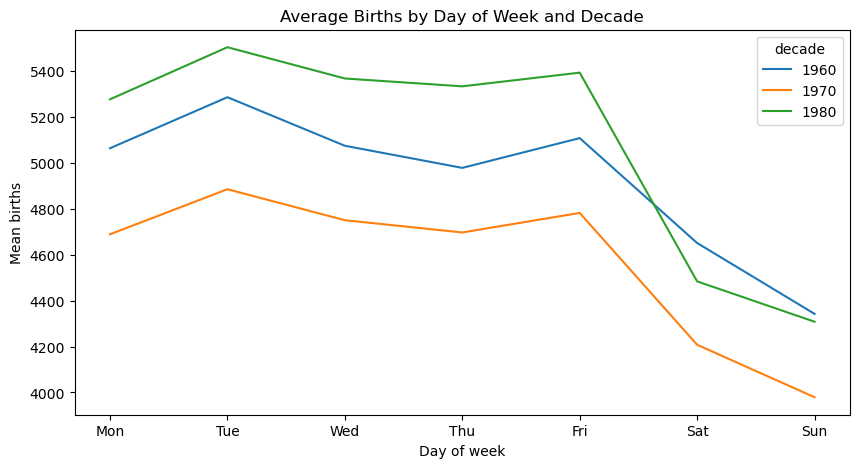

In [10]:
weekday_decade = pd.pivot_table(
    clean_births,
    values="births",
    index="dayofweek",
    columns="decade",
    aggfunc="mean"
)

# Give the weekday numbers readable labels
weekday_decade.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

weekday_decade.plot(
    title="Average Births by Day of Week and Decade",
    xlabel="Day of week",
    ylabel="Mean births",
    figsize=(10, 5)
);

In [11]:
print("Decades in the cleaned data:")
print(sorted(clean_births["decade"].unique()))

Decades in the cleaned data:
[1960, 1970, 1980]


In [12]:
month_day_births = pd.pivot_table(
    clean_births,
    values="births",
    index=["month", "day"],
    aggfunc="mean"
)

display(month_day_births.head())

births
month day          
1     1    4009.225
      2    4247.400
      3    4500.900
      4    4571.350
      5    4603.625

In [13]:
# Turn the month/day multi-index into dates using leap year 2012
month_day_index = month_day_births.index

calendar_dates = pd.to_datetime({
    "year": 2012,
    "month": month_day_index.get_level_values("month"),
    "day": month_day_index.get_level_values("day")
})

# Use the calendar date as the index for plotting
day_of_year = month_day_births.copy()
day_of_year.index = calendar_dates
day_of_year = day_of_year.sort_index()

display(day_of_year.head())

,births
2012-01-01,4009.225
2012-01-02,4247.400
2012-01-03,4500.900
2012-01-04,4571.350
2012-01-05,4603.625


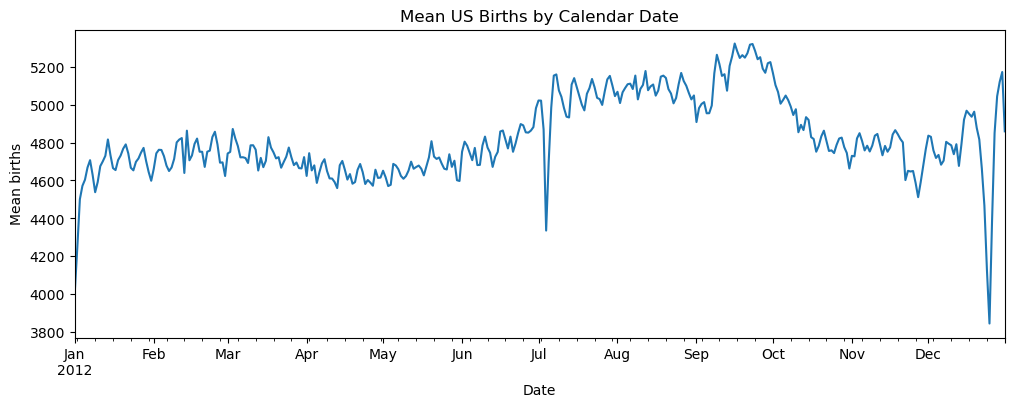

In [14]:
day_of_year.plot(
    title="Mean US Births by Calendar Date",
    xlabel="Date",
    ylabel="Mean births",
    figsize=(12, 4),
    legend=False
);

In [15]:
groupby_table = (
    clean_births
    .groupby(["decade", "gender"])["births"]
    .sum()
    .unstack()
)

display(groupby_table)

gender,F,M
decade,,
1960,1752836,1845742
1970,16260348,17118785
1980,16336507,17171290


In [16]:
# Recalculate the pivot table from the same cleaned data for a fair comparison
pivot_table_clean = pd.pivot_table(
    clean_births,
    values="births",
    index="decade",
    columns="gender",
    aggfunc="sum"
)

print("Do the pivot table and groupby results match?")
print(groupby_table.equals(pivot_table_clean))

Do the pivot table and groupby results match?
True


In [18]:
%timeit pd.pivot_table(clean_births, values="births", index="decade",columns="gender", aggfunc="sum")

%timeit clean_births.groupby(["decade", "gender"])["births"].sum().unstack()

9.89 ms ± 756 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)
3.92 ms ± 139 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [19]:
lowest_five_dates = day_of_year.nsmallest(5, "births")
display(lowest_five_dates)

,births
2012-12-25,3844.450
2012-01-01,4009.225
2012-12-24,4126.250
2012-01-02,4247.400
2012-07-04,4335.325


,births
2012-12-25,3844.450
2012-01-01,4009.225
2012-12-24,4126.250
2012-01-02,4247.400
2012-07-04,4335.325


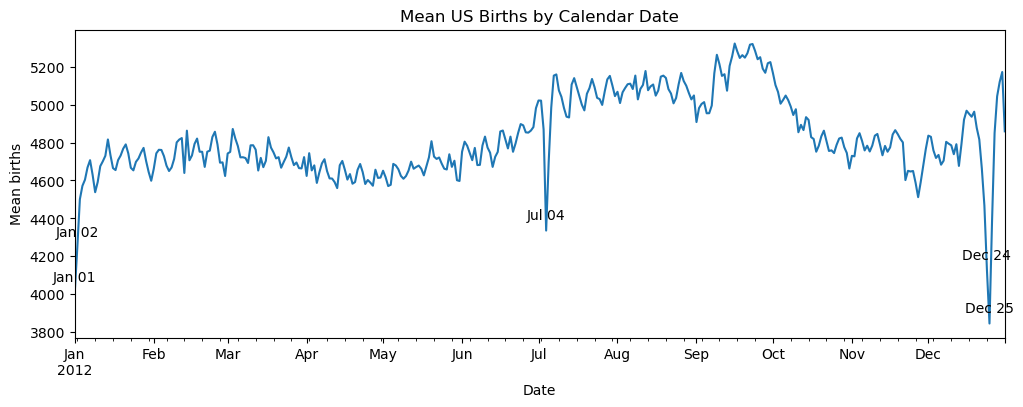

In [20]:
ax = day_of_year.plot(
    title="Mean US Births by Calendar Date",
    xlabel="Date",
    ylabel="Mean births",
    figsize=(12, 4),
    legend=False
)

# Add labels to the five lowest dates
for date, row in lowest_five_dates.iterrows():
    ax.annotate(
        date.strftime("%b %d"),
        xy=(date, row["births"]),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center"
    );

display(lowest_five_dates)